# Applying the XGBoost Algorithm

So far you've learned to apply a variety of different models. In this notebook you should prepare the data, import the XGBClassifier, train it and make predictions on your own. (Feel free to tune the hyperparameters in the end using a grid or random search!). 

We'll use the pima-native-americans-diabetic dataset for this task. You can find it in the data folder. You will see that the dataset is lacking column names. Therefore we added them as a list in one of the cells below. Have a look at the documentation. It is possible to import the data and directly add the columns names (they are in the correct order). 

If you need help or inspiration you can have a look at this [blogpost](https://machinelearningmastery.com/develop-first-xgboost-model-python-scikit-learn/), describing how to use the XGBoost Algorithm. 

## Learning Objectives

At the end of this notebook, you should be able to:

- Train an XGBoost classifier on a real medical dataset.
- Evaluate a classifier with a classification report and a confusion matrix.
- Rank feature importances to see which inputs drive the predictions.
- Map and visualise a model's decision surface over a grid of feature values.

## Import and Setup

In [1]:
# Import modules
from xgboost import XGBClassifier

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix)

import warnings
warnings.filterwarnings("ignore")

# same seed as notebook 1, so the split is the same too
RSEED = 42

In [2]:
# Import data
column_names = [
    "pregnancies",
    "glucose",
    "blood_pressure",
    "skin_thickness",
    "insulin",
    "bmi",
    "diabetes_pedigree_function",
    "age",
    "outcome",
]
# the file has no header row: names= gives the columns their names on import
df = pd.read_csv("data/pima-native-americans-diabetes.csv",
                 header=None, names=column_names)
df.head()

,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree_function,age,outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
# Quick look: size, class balance, and zeros that really mean "not measured"
print(df.shape)
print(df["outcome"].value_counts())
print((df[["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]] == 0).sum())

(768, 9)
outcome
0    500
1    268
Name: count, dtype: int64
glucose             5
blood_pressure     35
skin_thickness    227
insulin           374
bmi                11
dtype: int64


Some columns hold `0` where a value was simply not measured (nobody has a blood pressure or BMI of 0). We leave them as they are: tree models like XGBoost can split such zeros off on their own, and notebook 1 used the same raw data, so the scores stay comparable.

In [4]:
# Split the data
# same split as notebook 1: 25 % test, stratified, seed 42
X = df.drop("outcome", axis=1)
y = df["outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, stratify=y, random_state=RSEED
)
X_train.shape, X_test.shape

((576, 8), (192, 8))

In [5]:
# Fit model to training data
# default settings first: 100 trees, depth 6, learning rate 0.3
xgb = XGBClassifier(random_state=RSEED, n_jobs=-1)
xgb.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [6]:
# Make predictions on test set
y_pred = xgb.predict(X_test)
y_pred[:10]

array([0, 0, 0, 0, 1, 0, 0, 0, 1, 0])

In [7]:
# Evaluate your model
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"F1 score: {f1_score(y_test, y_pred):.3f}")
print(f"Recall:   {recall_score(y_test, y_pred):.3f}")
# the same model on the rows it learned from: a big gap = overfitting
train_acc = accuracy_score(y_train, xgb.predict(X_train))
print(f"Accuracy on the training rows: {train_acc:.3f}")
print()
print(classification_report(y_test, y_pred))

Accuracy: 0.729
F1 score: 0.612
Recall:   0.612
Accuracy on the training rows: 1.000

              precision    recall  f1-score   support

           0       0.79      0.79      0.79       125
           1       0.61      0.61      0.61        67

    accuracy                           0.73       192
   macro avg       0.70      0.70      0.70       192
weighted avg       0.73      0.73      0.73       192



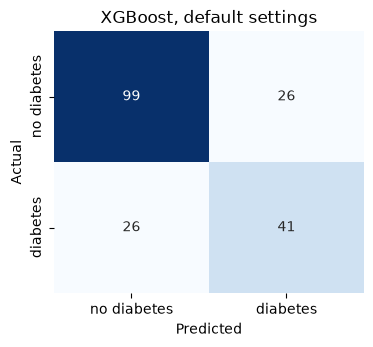

In [8]:
# Confusion matrix: rows = truth, columns = prediction
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4, 3.4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["no diabetes", "diabetes"],
            yticklabels=["no diabetes", "diabetes"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("XGBoost, default settings")
plt.show()

**What we see.** With its default settings XGBoost reaches 0.729 accuracy, an F1 of 0.612 and a recall of 0.612 on the 192 test patients. Of the 67 patients with diabetes it finds 41 and misses 26, and it raises 26 false alarms among the 125 patients without diabetes.

That is no better than the single models of notebook 1 (0.69 to 0.75 accuracy). The reason shows in the training score: on the 576 rows it learned from, the model is right every time (1.000). The default trees are deep (depth 6), so with this little data XGBoost memorises the training rows instead of learning a general rule. That is overfitting, and tuning should reduce it.

## Feature Importance

Every tree in XGBoost splits on features. `feature_importances_` adds up how useful each feature's splits were, scaled so all eight sum to 1.

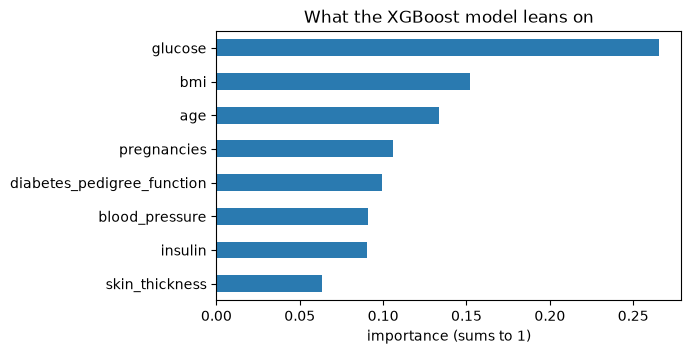

glucose                       0.266
bmi                           0.152
age                           0.133
pregnancies                   0.106
diabetes_pedigree_function    0.099
blood_pressure                0.091
insulin                       0.090
skin_thickness                0.063
dtype: float32

In [9]:
# Rank the features by importance
imp = pd.Series(xgb.feature_importances_, index=X_train.columns)
imp = imp.sort_values()
ax = imp.plot.barh(figsize=(6, 3.5), color="#2a7ab0")
ax.set_xlabel("importance (sums to 1)")
ax.set_title("What the XGBoost model leans on")
plt.show()
imp.sort_values(ascending=False).round(3)

**What we see.** Glucose (blood sugar after a glucose test) is by far the most used feature (0.266), followed by BMI (0.152) and age (0.133). Skin thickness matters least (0.063). This fits medical knowledge: a high blood sugar level is the main sign of diabetes.

Keep in mind that importance only says how much the model *used* a feature for its splits. It does not prove that the feature *causes* the outcome, and correlated features can share or steal each other's importance.

## Tuning the Hyperparameters

The defaults are a starting point. With a small grid search we try combinations of tree depth, learning rate, number of trees and row sampling. Each combination is scored by 5-fold cross-validation on the **training set only**, so the test set stays unseen. We score by F1, because on this imbalanced medical data finding the diabetic patients matters more than plain accuracy.

In [10]:
# Grid of settings to try: 3 x 3 x 2 x 2 = 36 combinations
param_grid = {
    "max_depth": [2, 3, 4],
    "learning_rate": [0.03, 0.1, 0.3],
    "n_estimators": [100, 300],
    "subsample": [0.8, 1.0],
}
search = GridSearchCV(
    XGBClassifier(random_state=RSEED, n_jobs=1),
    param_grid, scoring="f1", cv=5, n_jobs=-1,
)
search.fit(X_train, y_train)
print("best settings:", search.best_params_)
print(f"best cross-validated F1: {search.best_score_:.3f}")
# how close were the runners-up? (mean and spread over the 5 folds)
cv = pd.DataFrame(search.cv_results_)
cv = cv.sort_values("rank_test_score").head(5)
# one column per setting, then the mean F1 and its spread over the folds
top5 = pd.DataFrame(list(cv["params"]))
top5["mean F1"] = cv["mean_test_score"].values
top5["spread (std)"] = cv["std_test_score"].values
top5.round(3)

best settings: {'learning_rate': 0.3, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}
best cross-validated F1: 0.638


,learning_rate,max_depth,n_estimators,subsample,mean F1,spread (std)
0,0.30,2,100,0.8,0.638,0.037
1,0.10,2,100,0.8,0.631,0.030
2,0.30,2,100,1.0,0.627,0.028
3,0.03,3,300,1.0,0.625,0.033
4,0.03,4,300,0.8,0.624,0.036


In [11]:
# Compare default and tuned model on the untouched test set
best_xgb = search.best_estimator_
y_pred_best = best_xgb.predict(X_test)
rows = []
for name, m, pred in [("default", xgb, y_pred),
                      ("tuned", best_xgb, y_pred_best)]:
    rows.append({
        "model": name,
        "train accuracy": accuracy_score(y_train, m.predict(X_train)),
        "accuracy": accuracy_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "recall": recall_score(y_test, pred),
    })
pd.DataFrame(rows).set_index("model").round(3)

,train accuracy,accuracy,F1,recall
model,,,,
default,1.000,0.729,0.612,0.612
tuned,0.915,0.734,0.592,0.552


**What we see.** The search picked shallow trees (`max_depth=2`), `learning_rate=0.3`, 100 trees and 80 % row sampling, with a cross-validated F1 of 0.638.

The tuned model overfits much less: training accuracy 0.915 instead of 1.000. On the test set, however, it is not clearly better. Accuracy rises a little (0.734 vs 0.729), but F1 drops (0.592 vs 0.612) and so does recall (0.552 vs 0.612): it finds 37 instead of 41 diabetic patients. Two honest reasons:

- The runners-up in the search scored almost the same (0.624 to 0.631) and the spread between folds is about 0.03 to 0.04. The "best" setting wins partly by luck.
- The test set is small: with 67 positive patients, one patient more or less moves recall by 1.5 percentage points.

So tuning made the model simpler and more stable, but on this small dataset it did not buy a better test score. For a medical screen, where a missed patient is the costly error, we would rather tune for recall or lower the decision threshold.

## Mapping the Decision Surface

A score tells us *how often* the model is right. A decision surface shows *how* it thinks. We build a grid of glucose and BMI values, keep every other feature at its training median, and ask the tuned model for the probability of diabetes at every point of the grid.

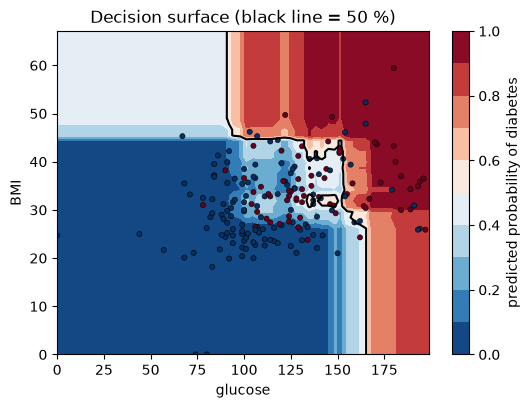

In [12]:
# Build a 60 x 60 grid of glucose and BMI values
# the grid spans every value in the data, so all test points sit on the map
g = np.linspace(X["glucose"].min(), X["glucose"].max(), 60)
b = np.linspace(X["bmi"].min(), X["bmi"].max(), 60)
gg, bb = np.meshgrid(g, b)
# every other feature stays at its typical (median) value
grid = pd.DataFrame([X_train.median()] * gg.size).reset_index(drop=True)
grid["glucose"] = gg.ravel()
grid["bmi"] = bb.ravel()
prob = best_xgb.predict_proba(grid[X_train.columns])[:, 1].reshape(gg.shape)

fig, ax = plt.subplots(figsize=(6, 4.2))
cs = ax.contourf(gg, bb, prob, levels=np.linspace(0, 1, 11), cmap="RdBu_r")
ax.contour(gg, bb, prob, levels=[0.5], colors="k", linewidths=1.5)
ax.scatter(X_test["glucose"], X_test["bmi"], c=y_test, cmap="RdBu_r",
           edgecolor="k", s=14, linewidths=0.4)
fig.colorbar(cs, label="predicted probability of diabetes")
ax.set_xlabel("glucose")
ax.set_ylabel("BMI")
ax.set_title("Decision surface (black line = 50 %)")
plt.show()

**What we see.** The map reads like a rule of thumb. Below a glucose of about 90 the model says "no diabetes" for every BMI. Above about 165 it says "diabetes" for every BMI. In between, BMI decides: above a BMI of roughly 42 the probability turns red, below it mostly stays blue, with a mixed zone around glucose 125 to 155.

The borders are steps, not smooth curves, because every tree splits at fixed thresholds (for example "glucose below 127.5?"). The red dots inside the blue area are diabetic patients the model misses: their glucose and BMI look like those of healthy patients. This view holds the other six features at their median, so it is a slice through the model, not the whole picture.

## Summary

In this notebook we:

- Loaded the diabetes data with its column names (`names=`) and kept the same stratified split as notebook 1.
- Trained an `XGBClassifier` with default settings and evaluated it with a classification report and a confusion matrix.
- Found that the defaults overfit (training accuracy 1.000, test 0.729).
- Ranked the features: glucose, BMI and age drive the predictions.
- Tuned depth, learning rate, number of trees and row sampling with a 5-fold grid search (36 combinations).
- Mapped the tuned model's decision surface over glucose and BMI.

| Model | Train accuracy | Test accuracy | F1 | Recall |
|---|---|---|---|---|
| XGBoost, default | 1.000 | 0.729 | 0.612 | 0.612 |
| XGBoost, tuned | 0.915 | 0.734 | 0.592 | 0.552 |
| Best ensemble of notebook 1 (soft voting) | | 0.766 | | |

On 768 patients a strong boosting library is no magic bullet: the small voting ensemble of notebook 1 scored higher. Boosting shines on larger datasets, as notebook 3 shows.